### PowerTransformer

`PowerTransformer` is a Scikit-learn transformer that makes numerical features more Gaussian-like (less skewed) using power transformations.

It supports two methods:
- **Box-Cox :** requires strictly positive values.
- **Yeo-Johnson :** supports positive, zero, and negative values.

It estimates a parameter (`lambda`) for each feature to determine the transformation. By default, it also standardizes the transformed features.

**Why use it ?**
- Reduce feature skewness.
- Make numerical distributions more symmetric.
- Potentially improve models that benefit from more Gaussian-like features, such as Linear Regression.

Fit the transformer on training data, then use the same fitted transformer to transform test data.

In [1]:
import numpy as np 
import pandas as pd 

import seaborn as sns 
import matplotlib.pyplot as plt 

import scipy.stats as stats

In [2]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sklearn.preprocessing import PowerTransformer

In [3]:
df = pd.read_csv('Datasets/concrete_data.csv')
df.head()

,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age,Strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30


In [4]:
df.shape

(1030, 9)

In [5]:
df.isnull().sum()

Cement                0
Blast Furnace Slag    0
Fly Ash               0
Water                 0
Superplasticizer      0
Coarse Aggregate      0
Fine Aggregate        0
Age                   0
Strength              0
dtype: int64

In [6]:
df.describe()

,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age,Strength
count,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000
mean,281.167864,73.895825,54.188350,181.567282,6.204660,972.918932,773.580485,45.662136,35.817961
std,104.506364,86.279342,63.997004,21.354219,5.973841,77.753954,80.175980,63.169912,16.705742
min,102.000000,0.000000,0.000000,121.800000,0.000000,801.000000,594.000000,1.000000,2.330000
25%,192.375000,0.000000,0.000000,164.900000,0.000000,932.000000,730.950000,7.000000,23.710000
50%,272.900000,22.000000,0.000000,185.000000,6.400000,968.000000,779.500000,28.000000,34.445000
75%,350.000000,142.950000,118.300000,192.000000,10.200000,1029.400000,824.000000,56.000000,46.135000
max,540.000000,359.400000,200.100000,247.000000,32.200000,1145.000000,992.600000,365.000000,82.600000


In [7]:
X = df.drop(columns=['Strength'])
y = df.iloc[:, -1]

In [8]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [9]:
X_train

,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age
995,158.6,148.9,116.0,175.1,15.0,953.3,719.7,28
507,424.0,22.0,132.0,178.0,8.5,822.0,750.0,28
334,275.1,0.0,121.4,159.5,9.9,1053.6,777.5,3
848,252.0,97.0,76.0,194.0,8.0,835.0,821.0,28
294,168.9,42.2,124.3,158.3,10.8,1080.8,796.2,3
...,...,...,...,...,...,...,...,...
87,286.3,200.9,0.0,144.7,11.2,1004.6,803.7,3
330,246.8,0.0,125.1,143.3,12.0,1086.8,800.9,14
466,190.3,0.0,125.2,166.6,9.9,1079.0,798.9,100
121,475.0,118.8,0.0,181.1,8.9,852.1,781.5,28


In [10]:
y_train

995    27.68
507    62.05
334    23.80
848    33.40
294     7.40
       ...  
87     24.40
330    42.22
466    33.56
121    68.30
860    38.46
Name: Strength, Length: 824, dtype: float64

#### Train Model without Applying Transformer

In [11]:
lr = LinearRegression()

lr.fit(X_train, y_train)

y_pred = lr.predict(X_test)

print(f'R2 Score : {r2_score(y_test, y_pred)}')

R2 Score : 0.6275531792314848


In [12]:
# cross checking with cross val score 
lr = LinearRegression()

np.mean(cross_val_score(lr, X, y, scoring='r2', cv=5))

np.float64(0.4609940491662864)

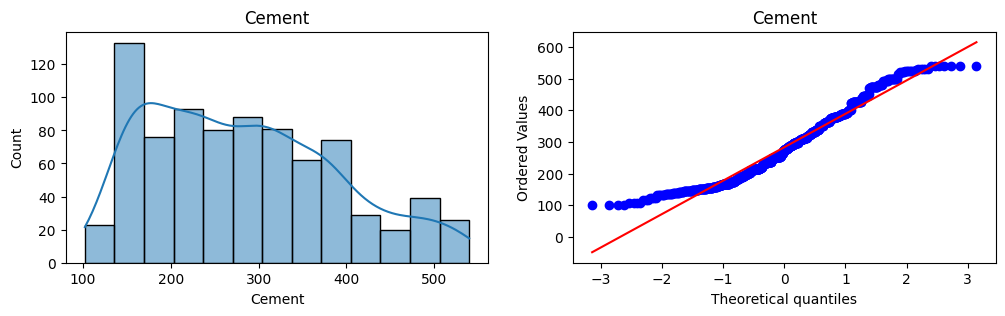

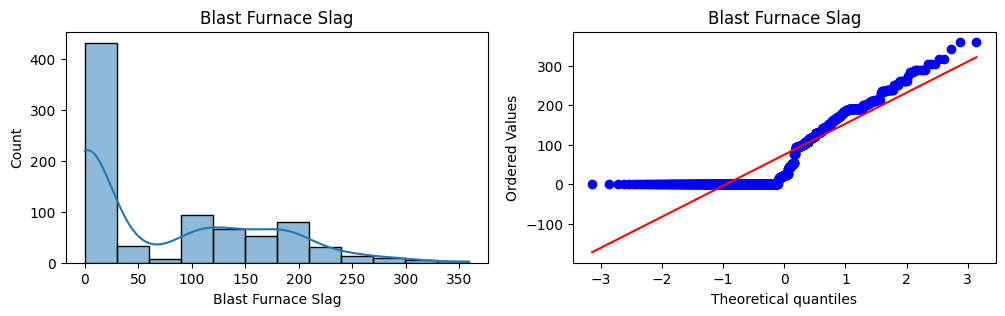

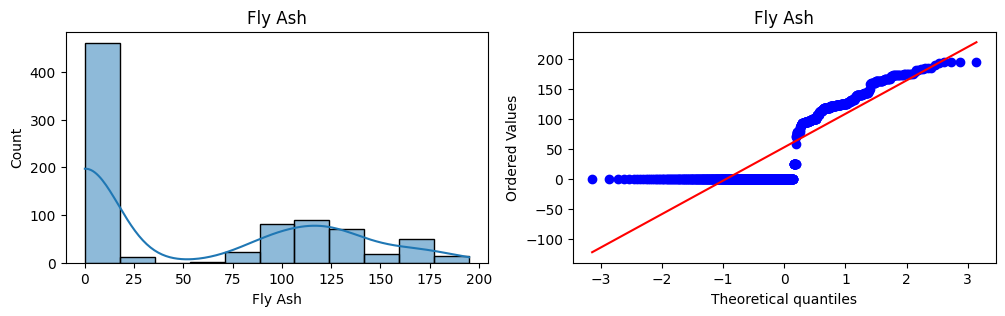

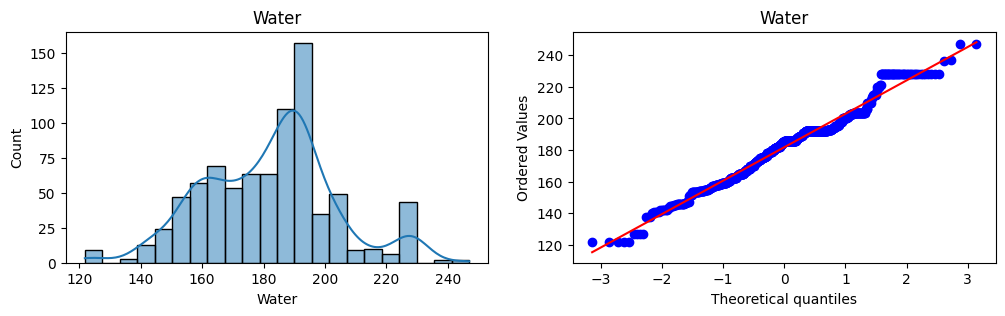

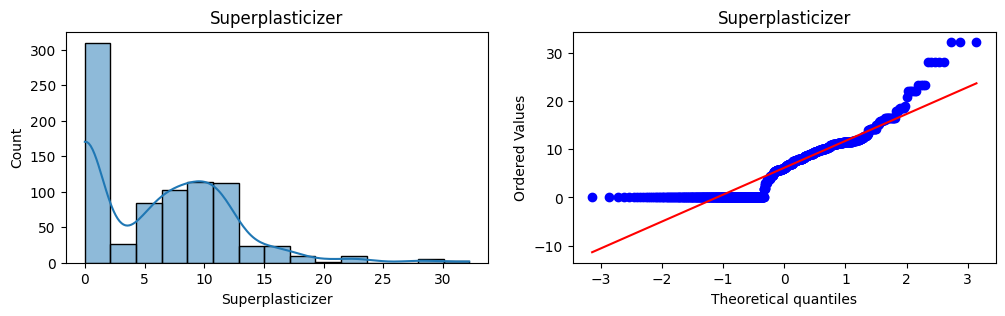

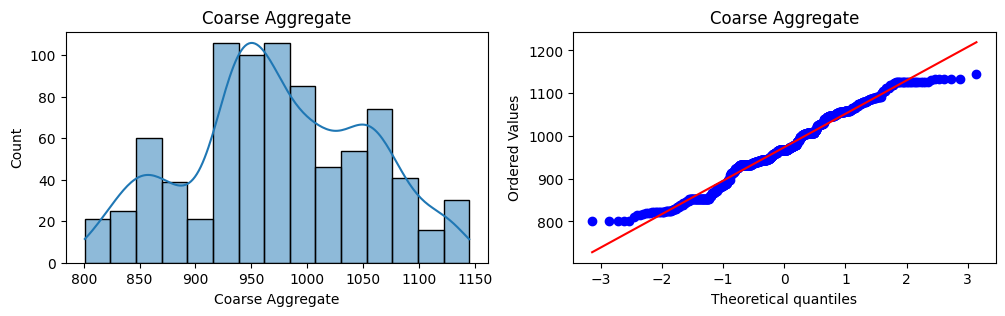

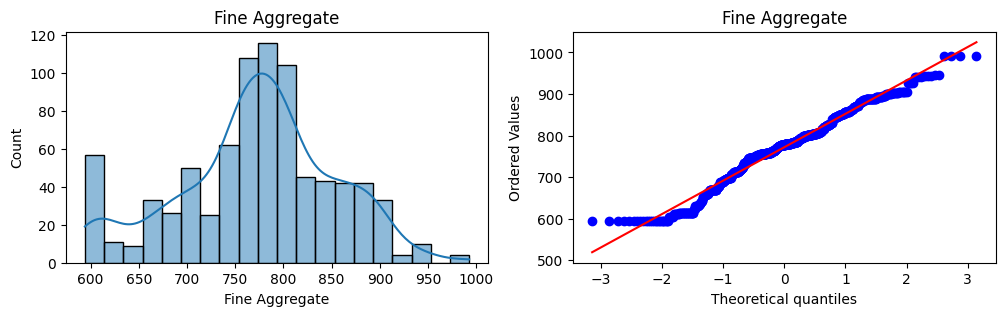

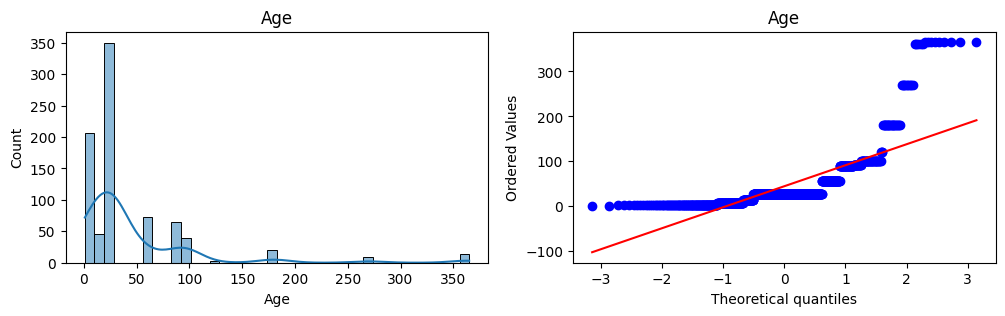

In [13]:
# ploting displot without applying any transformer 

for col in X_train.columns: 
    plt.figure(figsize=(12,3))
    plt.subplot(121)
    sns.histplot(X_train[col], kde=True)
    plt.title(col)

    plt.subplot(122)
    stats.probplot(X_train[col], dist="norm", plot=plt)
    plt.title(col)

    plt.show()

#### Applying Box-cox Transformer 

In [14]:
pt = PowerTransformer(method='box-cox')

X_train_transformed = pt.fit_transform(X_train+0.000001) # add some value because we have 0 in data
X_test_transformed = pt.fit_transform(X_test+0.000001)

pd.DataFrame({'cols' : X_train.columns, 'box_cox_lambdas': pt.lambdas_})

,cols,box_cox_lambdas
0,Cement,0.215602
1,Blast Furnace Slag,0.025996
2,Fly Ash,-0.006544
3,Water,0.959062
4,Superplasticizer,0.103365
5,Coarse Aggregate,1.192492
6,Fine Aggregate,1.973781
7,Age,-0.014692


In [15]:
X_train_transformed

array([[-1.27975148,  0.9561511 ,  1.12804495, ..., -0.26250008,
        -0.67756847,  0.10600969],
       [ 1.24470596,  0.70199413,  1.13757676, ..., -1.91272791,
        -0.3140622 ,  0.10600969],
       [ 0.07984236, -1.08566729,  1.13140696, ...,  1.01840672,
         0.02595744, -1.67597001],
       ...,
       [-0.84451727, -1.08566729,  1.13368097, ...,  1.34536665,
         0.29715694,  1.24673336],
       [ 1.5656235 ,  0.92549636, -0.88721185, ..., -1.5372548 ,
         0.0762111 ,  0.10600969],
       [ 0.42655631, -1.08566729,  1.12610617, ..., -0.62083414,
         0.0951082 ,  0.10600969]])

In [16]:
# Applying LR on transformed data 
lr = LinearRegression()

lr.fit(X_train_transformed, y_train)

y_pred = lr.predict(X_test_transformed)

print(f'R2 Score : {r2_score(y_test, y_pred)}')

R2 Score : 0.8055320999414498


In [17]:
# cross checking with cross val score 
pt = PowerTransformer(method='box-cox')
X_transformed = pt.fit_transform(X+0.000001)

np.mean(cross_val_score(lr, X_transformed, y, scoring='r2', cv=10))

np.float64(0.64667647529256)

In [18]:
X_train_transformed_df = pd.DataFrame(X_train_transformed, columns=X_train.columns)

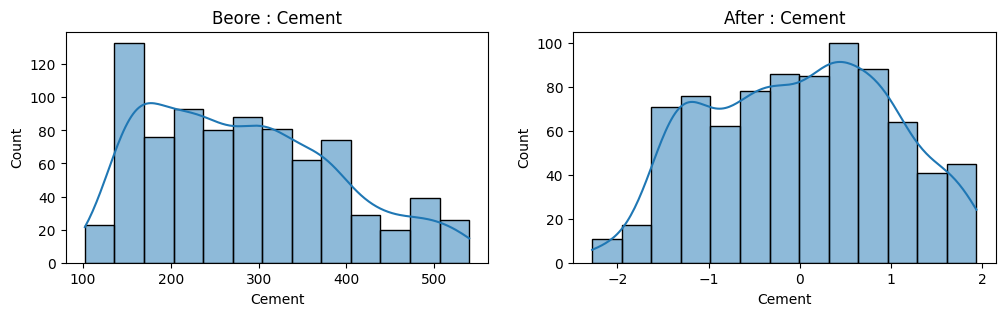

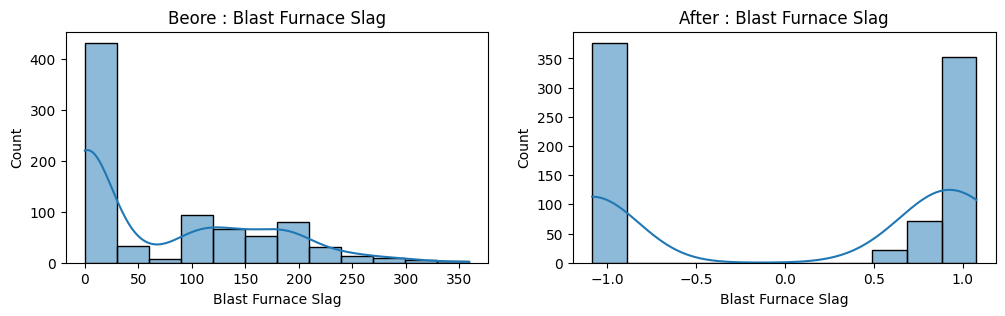

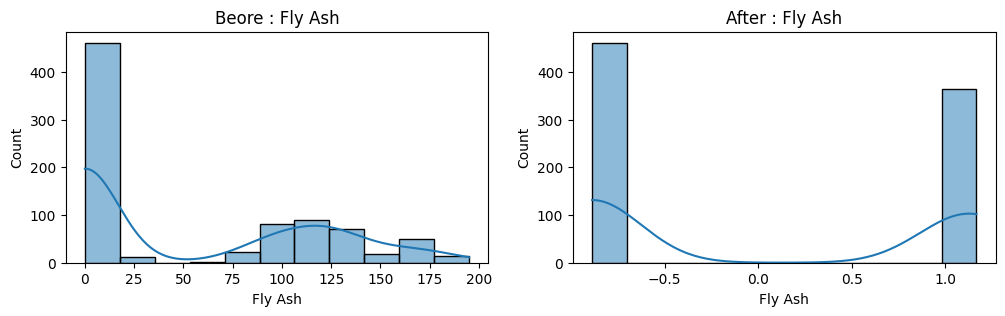

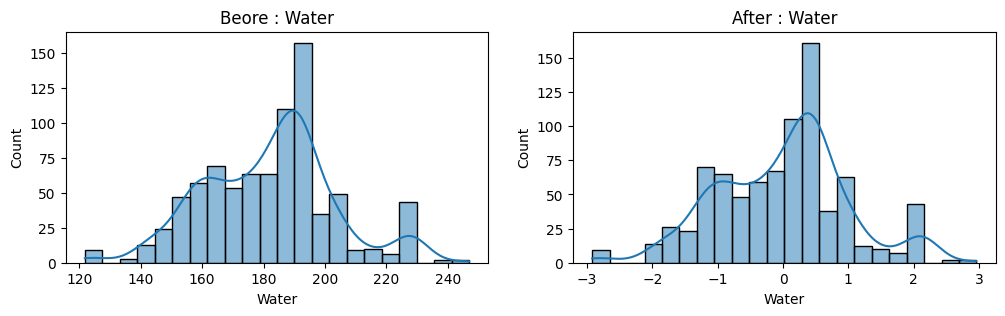

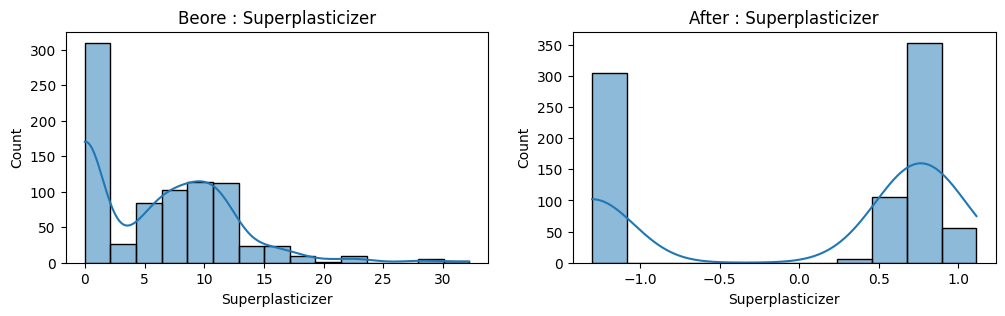

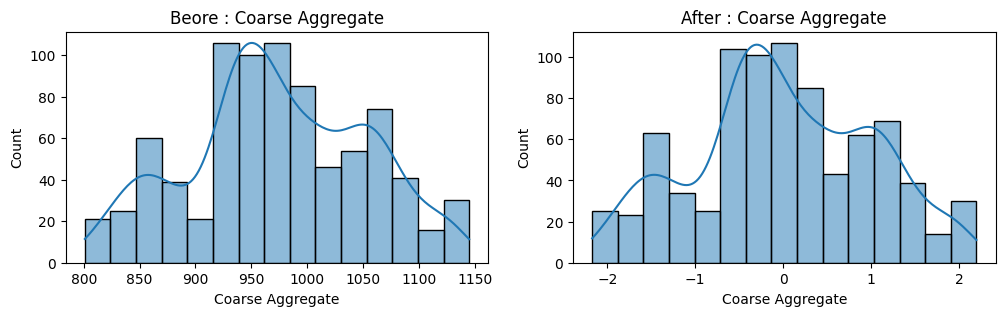

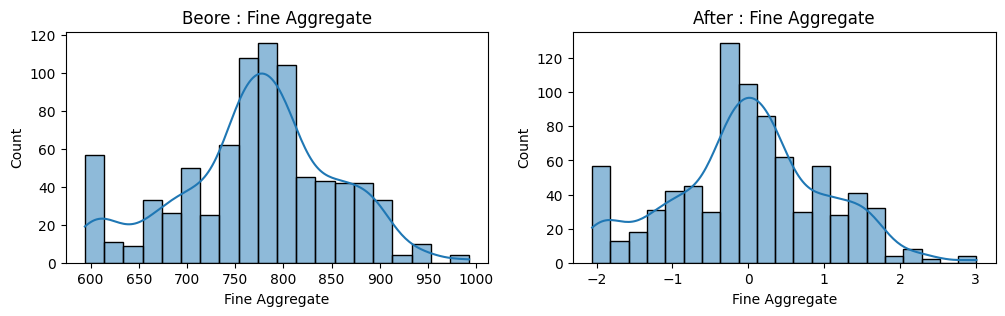

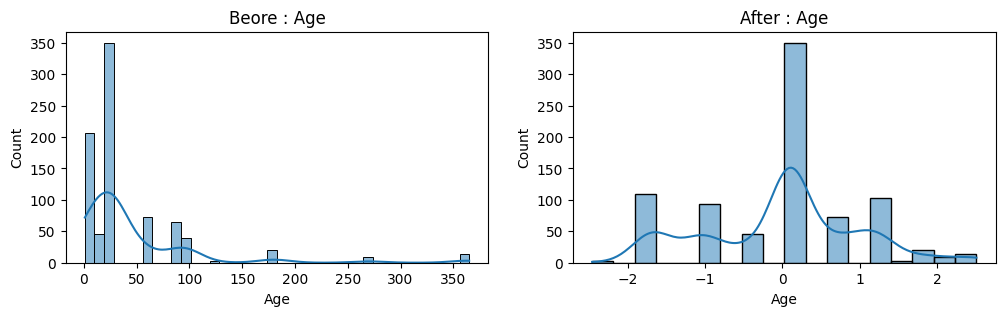

In [19]:
#### Before and after comparision for Box Cox Plot 
for col in X_train_transformed_df.columns: 
    plt.figure(figsize=(12,3))
    plt.subplot(121)
    sns.histplot(X_train[col], kde=True)
    plt.title(f'Beore : {col}')

    plt.subplot(122)
    sns.histplot(X_train_transformed_df[col], kde=True)
    plt.title(f'After : {col}')

    plt.show()